# Regularization and Gradient Descent Exercises
![UnderOverFit.png](Assets/UnderOverFit.png)


# Obiectivele învățării

- Explicarea funcțiilor de cost, regularizarea, selectarea caracteristicilor și hiperparametrii
- Rezumarea algoritmilor de optimizare statistică complexă, cum ar fi coborârea gradientului și aplicarea sa la regresia liniară



## Introducere

Vom începe cu un scurt tutorial despre regresie, caracteristici polinomiale și regularizare, bazat pe un set de date foarte simplu, rar, care conține o coloană de date `x` și date zgomotoase asociate `y`. Fișierul de date se numește `X_Y_Sinusoid_Data.csv`. 

In [1]:
from __future__ import print_function
import os
data_path = ['data']

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.linear_model import ElasticNetCV
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import MinMaxScaler



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## Întrebare 1

* Importați datele. 

* De asemenea, generați aproximativ 100 de puncte de date x egal distanțate pe intervalul 0-1. Folosind aceste puncte, calculați datele y care reprezintă „adevărul de bază” (funcția reală) din ecuația: $y = sin(2\pi x)$

* Reprezentați grafic datele rarefiate (`x` vs `y`) și datele calculate („reale”).


In [3]:
filepath = os.sep.join(data_path + ['X_Y_Sinusoid_Data.csv'])
data = pd.read_csv(filepath)
data.head()

,x,y
0,0.038571,0.066391
1,0.166776,1.027483
2,0.183153,1.245302
3,0.187359,1.004781
4,0.243116,1.264121


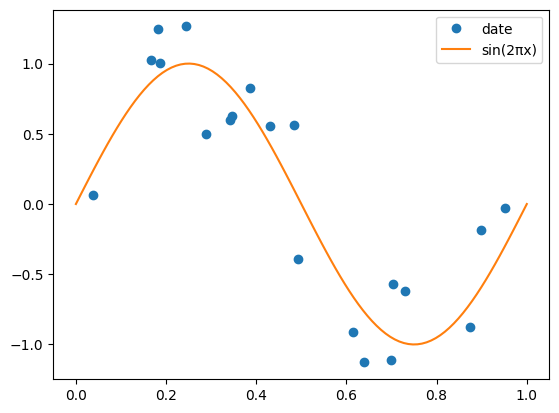

In [4]:
X_real = np.linspace(0, 1.0, 100)
Y_real = np.sin(2 * np.pi * X_real)

plt.plot(data['x'], data['y'], 'o', label='date')
plt.plot(X_real, Y_real, label='sin(2πx)')
plt.legend()
plt.show()

Punctele urmează forma sinusoidei, dar au zgomot. Sunt doar 20 de puncte, deci un model prea complex poate face ușor overfitting.

## Întrebarea 2


* Folosind clasa `PolynomialFeatures` din biblioteca de preprocesare Scikit-learn, creați caracteristici polinomiale de ordinul 20.
* Adaptați aceste date folosind regresia liniară. 
* Reprezentați grafic valoarea prezisă rezultată în comparație cu datele calculate.

Rețineți că `PolynomialFeatures` necesită fie un cadru de date (cu o coloană, nu o serie), fie o matrice 2D de dimensiune (`X`, 1), unde `X` este lungimea.

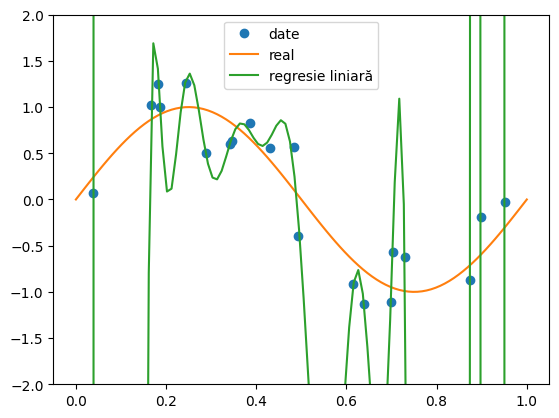

In [5]:
pf = PolynomialFeatures(degree=20)
X_pf = pf.fit_transform(data[['x']])
y = data['y']

lr = LinearRegression()
lr.fit(X_pf, y)

X_real_pf = pf.transform(pd.DataFrame({'x': X_real}))
Y_lr = lr.predict(X_real_pf)

plt.plot(data['x'], data['y'], 'o', label='date')
plt.plot(X_real, Y_real, label='real')
plt.plot(X_real, Y_lr, label='regresie liniară')
plt.ylim(-2, 2)
plt.legend()
plt.show()

Cu gradul 20 modelul încearcă să treacă prin toate punctele, iar între ele oscilează foarte mult (iese din grafic). E overfitting: curba nu seamănă deloc cu sinusoida reală.

## Întrebare 3

* Efectuați regresia pe baza datelor cu caracteristici polinomiale utilizând regresia Ridge ($\alpha$=0,001) și regresia Lasso ($\alpha$=0,0001). 
* Reprezentați grafic rezultatele, așa cum s-a făcut la întrebarea 1. 
* De asemenea, reprezentați grafic magnitudinea coeficienților obținuți din aceste regresii și comparați-i cu cei obținuți din regresia liniară din întrebarea anterioară. Coeficienții regresiei liniare vor necesita probabil un grafic separat (sau propria axă y) din cauza magnitudinii lor mari. 

Ce vă spune magnitudinea comparativ mare a datelor cu privire la rolul regularizării?

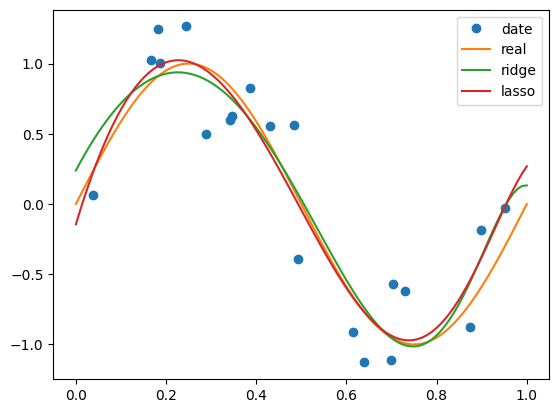

In [6]:
rr = Ridge(alpha=0.001)
rr.fit(X_pf, y)
Y_rr = rr.predict(X_real_pf)

lassor = Lasso(alpha=0.0001, max_iter=100000)
lassor.fit(X_pf, y)
Y_lassor = lassor.predict(X_real_pf)

plt.plot(data['x'], data['y'], 'o', label='date')
plt.plot(X_real, Y_real, label='real')
plt.plot(X_real, Y_rr, label='ridge')
plt.plot(X_real, Y_lassor, label='lasso')
plt.legend()
plt.show()

In [7]:
# let's look at the absolute value of coefficients for each model

coefficients = pd.DataFrame()
coefficients['linear regression'] = lr.coef_.ravel()
coefficients['ridge regression'] = rr.coef_.ravel()
coefficients['lasso regression'] = lassor.coef_.ravel()
coefficients = coefficients.abs()

coefficients.describe()  # Huge difference in scale between non-regularized vs regularized regression

,linear regression,ridge regression,lasso regression
count,2.100000e+01,21.000000,21.000000
mean,2.428398e+11,2.169397,2.665181
std,2.709297e+11,2.900278,6.772431
min,1.866829e+06,0.000000,0.000000
25%,3.076039e+10,0.467578,0.000000
50%,1.258276e+11,1.017272,0.000000
75%,3.630957e+11,2.883507,0.000000
max,9.200215e+11,12.429635,25.359652


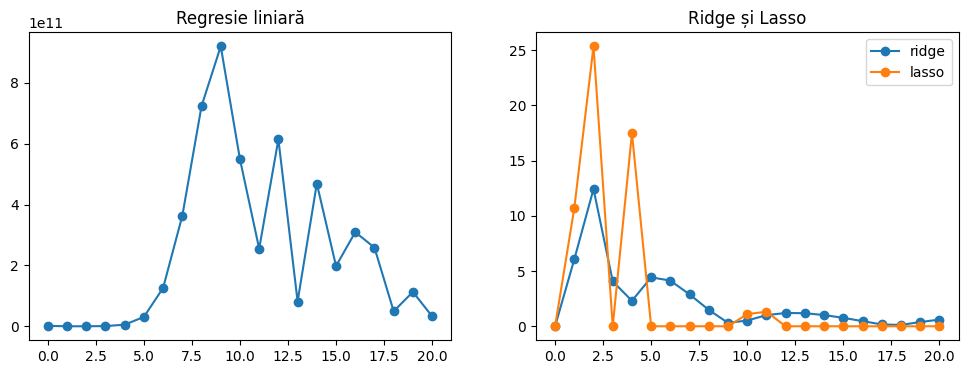

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(coefficients['linear regression'], marker='o')
axes[0].set_title('Regresie liniară')

axes[1].plot(coefficients['ridge regression'], marker='o', label='ridge')
axes[1].plot(coefficients['lasso regression'], marker='o', label='lasso')
axes[1].set_title('Ridge și Lasso')
axes[1].legend()

plt.show()

Coeficienții regresiei liniare sunt uriași (ajung la ~10¹¹), pe când la Ridge și Lasso sunt sub 30. Coeficienții mari arată un model prea complex, care urmărește zgomotul din date. Regularizarea îi micșorează și curba devine netedă, aproape de sinusoida reală. Lasso pune majoritatea coeficienților pe 0, adică folosește doar câteva puteri ale lui x.

## Întrebarea 4

Pentru întrebările rămase, vom lucra cu [setul de date](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) din lecția trecută, care se bazează pe prețurile locuințelor din Ames, Iowa. Există un număr mare de caracteristici - a se vedea exercițiile din săptămâna a treia pentru o discuție despre aceste caracteristici.

Pentru a începe:

* Importați datele cu Pandas, eliminați orice valori nule și o codificare fierbinte a categoriilor. Pot fi utilizate fie codificatoarele de caracteristici Scikit-learn, fie metoda Pandas `get_dummies`.
* Împărțiți datele în seturi de instruire și de testare. 
* Transformarea logaritmică a caracteristicilor distorsionate. 
* Se poate încerca scalarea, deși poate fi interesant să se vadă cât de bine funcționează regularizarea fără scalarea caracteristicilor.

In [9]:
filepath = os.sep.join(data_path + ['Ames_Housing_Sales.csv'])
data = pd.read_csv(filepath)
print(data.shape)
data.isnull().sum().sort_values(ascending=False).head(12)

(1379, 80)


PoolQC          1372
MiscFeature     1328
Alley           1297
Fence           1114
MasVnrType       797
FireplaceQu      618
BsmtFinType2     427
BsmtCond         426
BsmtFinType1     426
BsmtQual         426
BsmtExposure     426
2ndFlrSF           0
dtype: int64

Valorile lipsă sunt doar în coloanele categoriale (PoolQC, Alley, Fence etc.) și înseamnă de fapt că lipsește elementul respectiv (casa nu are piscină, gard etc.). Cu `dropna()` nu ar mai rămâne niciun rând, așa că nu șterg nimic. La `get_dummies` aceste valori devin automat 0 în toate coloanele noi.

Creați o listă de date categoriale și codificați one-hot. Pandas one-hot encoder (`get_dummies`) funcționează bine cu date care sunt definite ca fiind categoriale.

In [10]:
num_cols = data.select_dtypes(include='number').columns
cat_cols = data.select_dtypes(exclude='number').columns
print(len(num_cols), 'numerice,', len(cat_cols), 'categoriale')

data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=int)
data.shape

37 numerice, 43 categoriale


(1379, 241)

Apoi, împărțiți datele în seturi de date de instruire și de testare.

In [11]:
train, test = train_test_split(data, test_size=0.3, random_state=42)
print(train.shape, test.shape)

(965, 241) (414, 241)


Există o serie de coloane care au caracteristici înclinate - li se poate aplica o transformare logaritmică. Rețineți că aceasta include `SalePrice`, predictorul nostru. Cu toate acestea, să o păstrăm așa cum este.

Transformați toate coloanele în care deviația este mai mare de 0,75, cu excepția „SalePrice”.

In [12]:
skew_vals = train[num_cols].skew()
skew_cols = skew_vals[skew_vals > 0.75].index.drop('SalePrice')
print(len(skew_cols), 'coloane transformate')

for col in skew_cols:
    train[col] = np.log1p(train[col])
    test[col] = np.log1p(test[col])

23 coloane transformate


Separați datele dupa predictor

In [13]:
feature_cols = [c for c in train.columns if c != 'SalePrice']

X_train = train[feature_cols]
y_train = train['SalePrice']
X_test = test[feature_cols]
y_test = test['SalePrice']

## Întrebare 5

* Scrieți o funcție **`rmse`** care primește valorile de adevăr și predicție și returnează eroarea medie pătratică. Utilizați funcția `mean_squared_error` de la sklearn.  


In [14]:
def rmse(ytrue, ypredicted):
    return np.sqrt(mean_squared_error(ytrue, ypredicted))

* Adaptați un model de regresie liniară de bază
* tipăriți eroarea medie pătratică pentru acest model
* reprezentați grafic prețul de vânzare previzionat față de cel real pe baza modelului.  

RMSE: 41990.51181064204


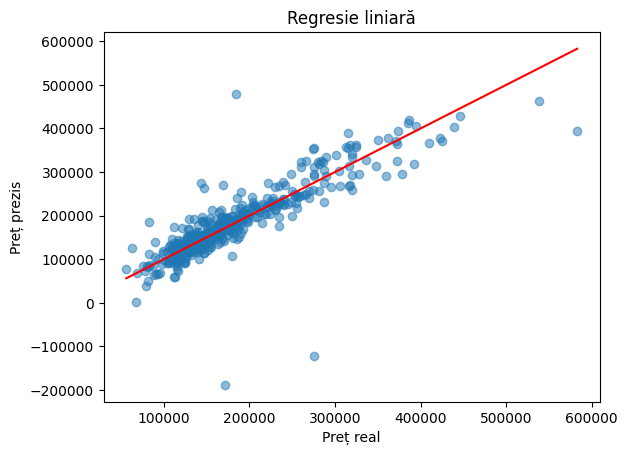

In [15]:
linearRegression = LinearRegression().fit(X_train, y_train)
y_pred_lr = linearRegression.predict(X_test)

linearRegression_rmse = rmse(y_test, y_pred_lr)
print('RMSE:', linearRegression_rmse)

plt.scatter(y_test, y_pred_lr, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r')
plt.xlabel('Preț real')
plt.ylabel('Preț prezis')
plt.title('Regresie liniară')
plt.show()

Linia roșie e predicția perfectă. Majoritatea punctelor sunt aproape de ea, dar sunt câteva case la care modelul greșește mult.

## Întrebarea 6

Regresia Ridge utilizează normalizarea L2 pentru a reduce magnitudinea coeficienților. Acest lucru poate fi util în situații în care există o varianță ridicată. Funcțiile de regularizare din Scikit-learn conțin fiecare versiuni care au validarea încrucișată încorporată.

* Adaptați un model Ridge regulat (nevalidat încrucișat) la o gamă de valori $\alpha$ și reprezentați grafic RMSE utilizând funcția de eroare validată încrucișat pe care ați creat-o mai sus.
* Utilizați $$[0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]$$ ca interval de alphas.
* Apoi repetați ajustarea modelelor Ridge folosind gama de valori $\alpha$ din secțiunea anterioară. Comparați rezultatele.

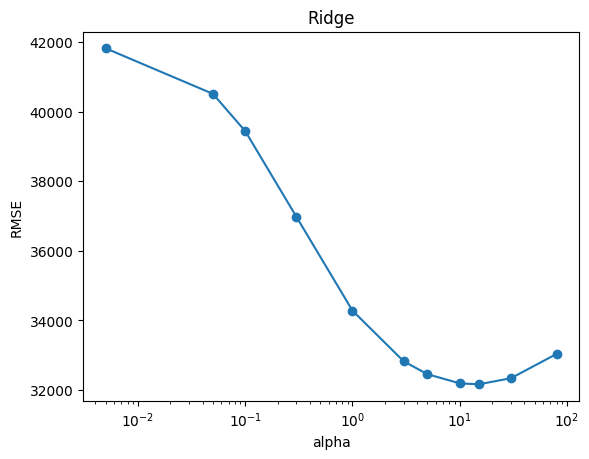

In [16]:
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

ridge_rmses = []
for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_train, y_train)
    ridge_rmses.append(rmse(y_test, ridge.predict(X_test)))

plt.semilogx(alphas, ridge_rmses, marker='o')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.title('Ridge')
plt.show()

Acum, pentru metoda `RidgeCV`. Din păcate, nu este posibil să obținem valorile alfa pentru modelele care nu au fost selectate. Valorile erorilor și valorile $\alpha$ rezultate sunt foarte asemănătoare cu cele obținute mai sus.

In [17]:
ridgeCV = RidgeCV(alphas=alphas, cv=4).fit(X_train, y_train)
ridgeCV_rmse = rmse(y_test, ridgeCV.predict(X_test))

print('alpha optim:', ridgeCV.alpha_)
print('RMSE:', ridgeCV_rmse)

alpha optim: 10.0
RMSE: 32194.329032970985


Eroarea scade până pe la alpha 10–15, apoi crește din nou. RidgeCV alege alpha = 10, foarte aproape de minimul de pe grafic. Ridge are o eroare mai mică decât regresia liniară simplă.

## Întrebarea 7


La fel ca funcția `RidgeCV`, există și o funcție `LassoCV` care utilizează o funcție de regularizare L1 și validarea încrucișată. Regularizarea L1 va micșora selectiv anumiți coeficienți, efectuând efectiv eliminarea caracteristicilor.

Funcția `LassoCV` nu permite setarea funcției de scor. Cu toate acestea, funcția de eroare personalizată (`rmse`) creată mai sus poate fi utilizată pentru a evalua eroarea modelului final.

În mod similar, există și o funcție elastic net cu validare încrucișată, `ElasticNetCV`, care este o combinație de regularizare L2 și L1.

* Potriviți un model Lasso utilizând validarea încrucișată și determinați valoarea optimă pentru $\alpha$ și RMSE utilizând funcția creată mai sus. Rețineți că magnitudinea lui $\alpha$ poate fi diferită de cea a modelului Ridge.
* Repetați operația cu modelul de plasă elastică.
* Comparați rezultatele prin tabel și/sau grafic.

Utilizați următoarele alphas:

`[1e-5, 5e-5, 0.0001, 0.0005]`

In [18]:
l1_alphas = [1e-5, 5e-5, 0.0001, 0.0005]

lassoCV = LassoCV(alphas=l1_alphas, max_iter=50000, cv=3).fit(X_train, y_train)
lassoCV_rmse = rmse(y_test, lassoCV.predict(X_test))

print('alpha optim:', lassoCV.alpha_)
print('RMSE:', lassoCV_rmse)

alpha optim: 0.0005
RMSE: 46032.87042245141


Putem determina câte dintre aceste caracteristici rămân diferite de zero.

In [19]:
print((lassoCV.coef_ != 0).sum(), 'din', len(lassoCV.coef_), 'coeficienți sunt diferiți de zero')

229 din 240 coeficienți sunt diferiți de zero


Încercați acum plasa elastică, cu aceleași alphas ca în Lasso, și l1_ratios între 0,1 și 0,9

In [20]:
l1_ratios = np.linspace(0.1, 0.9, 9)

elasticNetCV = ElasticNetCV(alphas=l1_alphas, l1_ratio=l1_ratios, max_iter=10000).fit(X_train, y_train)
elasticNetCV_rmse = rmse(y_test, elasticNetCV.predict(X_test))

print('alpha optim:', elasticNetCV.alpha_)
print('l1_ratio optim:', elasticNetCV.l1_ratio_)
print('RMSE:', elasticNetCV_rmse)

alpha optim: 0.0005
l1_ratio optim: 0.1
RMSE: 36069.37130427935


Compararea calculului RMSE din toate modelele este cea mai ușoară într-un tabel.

In [21]:
rmse_df = pd.DataFrame({'RMSE': [linearRegression_rmse, ridgeCV_rmse, lassoCV_rmse, elasticNetCV_rmse]},
                       index=['Linear', 'Ridge', 'Lasso', 'ElasticNet'])
rmse_df

,RMSE
Linear,41990.511811
Ridge,32194.329033
Lasso,46032.870422
ElasticNet,36069.371304


Putem, de asemenea, să realizăm un grafic al prețurilor reale și previzionate ale locuințelor, la fel ca înainte.

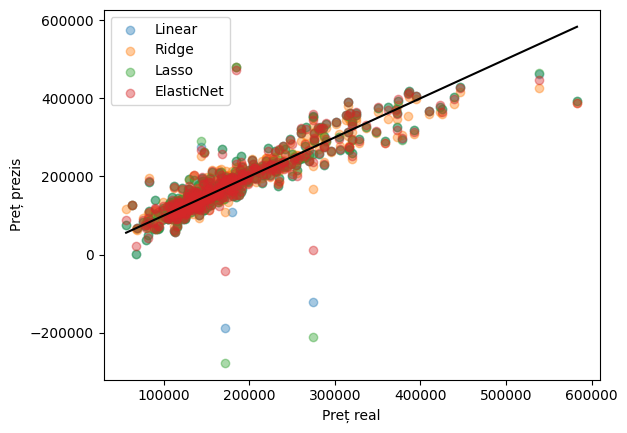

In [22]:
plt.scatter(y_test, y_pred_lr, alpha=0.4, label='Linear')
plt.scatter(y_test, ridgeCV.predict(X_test), alpha=0.4, label='Ridge')
plt.scatter(y_test, lassoCV.predict(X_test), alpha=0.4, label='Lasso')
plt.scatter(y_test, elasticNetCV.predict(X_test), alpha=0.4, label='ElasticNet')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k')
plt.xlabel('Preț real')
plt.ylabel('Preț prezis')
plt.legend()
plt.show()

Cel mai bun e Ridge, apoi ElasticNet. Lasso a ieșit chiar mai slab decât regresia liniară. Alpha ales e cel mai mare din listă (0.0005), deci probabil ar merge mai bine cu valori mai mari. Pe grafic diferențele se văd puțin, toate modelele urmează linia.

## Întrebarea 8

Să explorăm coborârea stochastică a gradientului în acest exercițiu.  
Reamintim că modelele liniare în general sunt sensibile la scalare.
Cu toate acestea, SGD este *foarte* sensibil la scalare.  
În plus, o valoare mare a ratei de învățare poate determina algoritmul să devieze, în timp ce o valoare prea mică poate dura prea mult până la convergență.

* Potriviți un model stochastic gradient descent fără o penalizare de regularizare (parametrul relevant este `penalty`).
* Ajustați acum modele stochastice de coborâre în gradient cu fiecare dintre cele trei penalizări (L2, L1, Elastic Net) folosind valorile parametrilor determinate prin validarea încrucișată de mai sus. 
* Nu scalați datele înainte de ajustarea modelului.  
* Comparați rezultatele cu cele obținute fără a utiliza coborârea stochastică în gradient.

In [23]:
model_parameters = {
    'Linear': {'penalty': None},
    'Ridge': {'penalty': 'l2', 'alpha': ridgeCV.alpha_},
    'Lasso': {'penalty': 'l1', 'alpha': lassoCV.alpha_},
    'ElasticNet': {'penalty': 'elasticnet', 'alpha': elasticNetCV.alpha_, 'l1_ratio': elasticNetCV.l1_ratio_}
}

sgd_rmses = {}
for name, params in model_parameters.items():
    sgd = SGDRegressor(**params, random_state=42).fit(X_train, y_train)
    sgd_rmses[name] = rmse(y_test, sgd.predict(X_test))

rmse_df['RMSE-SGD'] = pd.Series(sgd_rmses)
rmse_df

,RMSE,RMSE-SGD
Linear,41990.511811,7.425485e+14
Ridge,32194.329033,4.938915e+15
Lasso,46032.870422,7.425484e+14
ElasticNet,36069.371304,1.040881e+16


Observați cât de mari sunt valorile erorii! Algoritmul este divergent. Acest lucru se poate datora faptului că scalarea și/sau rata de învățare sunt prea mari. Să ajustăm rata de învățare și să vedem ce se întâmplă.

* Introduceți `eta0=1e-7` la crearea instanței de `SGDClassifier`.
* Calculați din nou erorile pentru toate penalitățile și comparați.

In [24]:
sgd_rmses = {}
for name, params in model_parameters.items():
    sgd = SGDRegressor(**params, eta0=1e-7, random_state=42).fit(X_train, y_train)
    sgd_rmses[name] = rmse(y_test, sgd.predict(X_test))

rmse_df['RMSE-SGD-eta0'] = pd.Series(sgd_rmses)
rmse_df

,RMSE,RMSE-SGD,RMSE-SGD-eta0
Linear,41990.511811,7.425485e+14,74751.945369
Ridge,32194.329033,4.938915e+15,74754.932321
Lasso,46032.870422,7.425484e+14,74751.945373
ElasticNet,36069.371304,1.040881e+16,74751.945504


Acum să ne scalăm datele de antrenament și să încercăm din nou.

* Adaptați un `MinMaxScaler` la `X_train` și creați o variabilă `X_train_scaled`.
* Folosind scala, transformați `X_test` și creați o variabilă `X_test_scaled`. 
* Aplicați-le aceleași versiuni ale SGD și comparați rezultatele. De data aceasta nu introduceți un eta0.

In [25]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

sgd_rmses = {}
for name, params in model_parameters.items():
    sgd = SGDRegressor(**params, random_state=42).fit(X_train_scaled, y_train)
    sgd_rmses[name] = rmse(y_test, sgd.predict(X_test_scaled))

rmse_df['RMSE-SGD-scaled'] = pd.Series(sgd_rmses)
rmse_df

,RMSE,RMSE-SGD,RMSE-SGD-eta0,RMSE-SGD-scaled
Linear,41990.511811,7.425485e+14,74751.945369,32579.633691
Ridge,32194.329033,4.938915e+15,74754.932321,71143.720262
Lasso,46032.870422,7.425484e+14,74751.945373,32579.625942
ElasticNet,36069.371304,1.040881e+16,74751.945504,32548.559180


Fără scalare SGD diverge și eroarea e enormă (~10¹⁵). Cu `eta0=1e-7` nu mai diverge, dar învață prea încet și eroarea rămâne mare (~75 000). După MinMaxScaler SGD ajunge aproape de rezultatele de mai sus (~32 500). Doar la Ridge eroarea rămâne mare, pentru că alpha = 10 luat din RidgeCV e prea mare pentru SGD. Concluzie: la SGD scalarea datelor e obligatorie.